# 속성 분류기 (Aspect Classifier)
## KLUE-RoBERTa 기반 멀티라벨 분류

입력: 리뷰 텍스트
출력: 언급된 속성 목록 (24개 중 복수 선택)

감정 분류기와 동일한 데이터 분할 기준 사용
- Index 기준 train/valid/test 분할
- random_state=42 고정

---
## STEP 0. 환경 설정

In [1]:
!pip install transformers torch scikit-learn pandas numpy matplotlib seaborn --quiet

import pandas as pd
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')

# 시드 고정 (감정 분류기와 동일)
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'디바이스: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
print('환경 설정 완료')

디바이스: cuda
GPU: Tesla T4
환경 설정 완료


---
## STEP 1. 데이터 로드 및 구조 확인

In [2]:
from google.colab import drive
drive.mount('/content/drive')
DATA_PATH = '/content/drive/MyDrive/'

df = pd.read_csv(DATA_PATH + 'bert_train_skincare_12k.csv')

print('=' * 60)
print('[STEP 1] CSV 기본 정보')
print('=' * 60)
print(f'전체 행 수      : {len(df):,}행')
print(f'고유 리뷰 수    : {df["Index"].nunique():,}개')
print(f'평균 Aspect 수  : {len(df) / df["Index"].nunique():.2f}개/리뷰')
print()
print('[Aspect 분포]')
aspect_counts = df['Aspect'].value_counts()
for aspect, count in aspect_counts.items():
    bar = '█' * int(count / len(df) * 50)
    print(f'  {aspect:20s}: {count:,}건 ({count/len(df)*100:.1f}%)  {bar}')

Mounted at /content/drive
[STEP 1] CSV 기본 정보
전체 행 수      : 38,603행
고유 리뷰 수    : 12,000개
평균 Aspect 수  : 3.22개/리뷰

[Aspect 분포]
  기능/효과               : 7,213건 (18.7%)  █████████
  보습력/수분감             : 7,039건 (18.2%)  █████████
  흡수력                 : 3,251건 (8.4%)  ████
  가격                  : 3,051건 (7.9%)  ███
  편의성/활용성             : 2,381건 (6.2%)  ███
  윤기/피부(톤)            : 2,376건 (6.2%)  ███
  제품구성                : 2,153건 (5.6%)  ██
  향                   : 1,804건 (4.7%)  ██
  발림성                 : 1,745건 (4.5%)  ██
  자극성                 : 1,290건 (3.3%)  █
  용량                  : 1,244건 (3.2%)  █
  제형                  : 993건 (2.6%)  █
  피부타입                : 771건 (2.0%)  
  탄력                  : 752건 (1.9%)  
  지속력                 : 743건 (1.9%)  
  품질                  : 457건 (1.2%)  
  용기                  : 358건 (0.9%)  
  유통기한                : 313건 (0.8%)  
  성분                  : 289건 (0.7%)  
  사용감                 : 283건 (0.7%)  
  디자인                 : 59건 (0.2%)  
  색상          

추가1

In [3]:
# 제외 속성 필터링
EXCLUDE_ASPECTS = ['밀착력/접착력', '커버력', '색상']

print('=' * 60)
print('[STEP 1-2] 제외 속성 필터링')
print('=' * 60)
print(f'제외 속성: {EXCLUDE_ASPECTS}')
print(f'필터링 전: {len(df):,}행')

df = df[~df['Aspect'].isin(EXCLUDE_ASPECTS)].reset_index(drop=True)

print(f'필터링 후: {len(df):,}행')
print(f'고유 리뷰 수: {df["Index"].nunique():,}개')
print()
print('[제외 후 Aspect 분포]')
for aspect, count in df['Aspect'].value_counts().items():
    print(f'  {aspect:20s}: {count:,}건')

[STEP 1-2] 제외 속성 필터링
제외 속성: ['밀착력/접착력', '커버력', '색상']
필터링 전: 38,603행
필터링 후: 38,565행
고유 리뷰 수: 12,000개

[제외 후 Aspect 분포]
  기능/효과               : 7,213건
  보습력/수분감             : 7,039건
  흡수력                 : 3,251건
  가격                  : 3,051건
  편의성/활용성             : 2,381건
  윤기/피부(톤)            : 2,376건
  제품구성                : 2,153건
  향                   : 1,804건
  발림성                 : 1,745건
  자극성                 : 1,290건
  용량                  : 1,244건
  제형                  : 993건
  피부타입                : 771건
  탄력                  : 752건
  지속력                 : 743건
  품질                  : 457건
  용기                  : 358건
  유통기한                : 313건
  성분                  : 289건
  사용감                 : 283건
  디자인                 : 59건


---
## STEP 2. 멀티라벨 변환

같은 Index(리뷰)에 여러 Aspect가 있으므로
Index 기준으로 그룹핑하여 멀티라벨로 변환

In [4]:
print('=' * 60)
print('[STEP 2] 멀티라벨 변환')
print('=' * 60)

# Index 기준으로 그룹핑 → 각 리뷰의 Aspect 목록 수집
grouped = df.groupby('Index').agg(
    RawText=('RawText', 'first'),
    Aspects=('Aspect', list)
).reset_index()

print(f'변환 전: {len(df):,}행 (행 단위)')
print(f'변환 후: {len(grouped):,}행 (리뷰 단위)')
print()

# 예시 확인
print('[변환 예시] 첫 3개 리뷰:')
for _, row in grouped.head(3).iterrows():
    print(f'  Index {row["Index"]}: {row["Aspects"]}')
    print(f'  RawText: "{row["RawText"][:50]}..."')
    print()

# MultiLabelBinarizer로 벡터 변환
mlb = MultiLabelBinarizer()
label_matrix = mlb.fit_transform(grouped['Aspects'])

print(f'[라벨 구조]')
print(f'  클래스 수    : {len(mlb.classes_)}개')
print(f'  클래스 목록  : {list(mlb.classes_)}')
print(f'  라벨 행렬    : {label_matrix.shape}  (리뷰 수 × 속성 수)')
print()

# 리뷰당 평균 속성 수 확인
labels_per_review = label_matrix.sum(axis=1)
print(f'[리뷰당 속성 수]')
print(f'  평균: {labels_per_review.mean():.2f}개')
print(f'  최소: {labels_per_review.min()}개')
print(f'  최대: {labels_per_review.max()}개')

# grouped에 라벨 추가
grouped['label_vector'] = list(label_matrix)

[STEP 2] 멀티라벨 변환
변환 전: 38,565행 (행 단위)
변환 후: 12,000행 (리뷰 단위)

[변환 예시] 첫 3개 리뷰:
  Index 215137: ['유통기한', '제품구성']
  RawText: "유통기한도 넉넉하고  구성도 많아서 선물 하기 좋네요.   만족합니다...."

  Index 215140: ['제품구성', '보습력/수분감']
  RawText: "구성도알차고촉촉하고너무좋아용..."

  Index 215143: ['용량', '자극성', '제품구성', '가격']
  RawText: "대용량으로 넉넉하게 사용할 수 있고 무난하고 순한 편이네요 제품 구성은 좋으나 가격면에서 ..."

[라벨 구조]
  클래스 수    : 21개
  클래스 목록  : ['가격', '기능/효과', '디자인', '발림성', '보습력/수분감', '사용감', '성분', '용기', '용량', '유통기한', '윤기/피부(톤)', '자극성', '제품구성', '제형', '지속력', '탄력', '편의성/활용성', '품질', '피부타입', '향', '흡수력']
  라벨 행렬    : (12000, 21)  (리뷰 수 × 속성 수)

[리뷰당 속성 수]
  평균: 2.73개
  최소: 1개
  최대: 8개


---
## STEP 3. [이전 방식 문제 증명] 행 단위 분할 시 누수 확인

감정 분류기와 동일하게 누수 문제를 먼저 증명

In [5]:
print('=' * 60)
print('[STEP 3] 행 단위 분할 시 누수 문제 확인')
print('=' * 60)

# 행 단위로 분할하면 어떻게 되는지
old_train, old_test = train_test_split(df, test_size=0.2, random_state=42)
overlap = set(old_train['Index']) & set(old_test['Index'])
print(f'행 단위 분할 시 겹치는 리뷰: {len(overlap)}개 ({len(overlap)/df["Index"].nunique()*100:.1f}% 누수)')
print('→ Index 기준 분할 필요!')
print()

# 올바른 방식: Index 기준 분할
unique_ids = grouped['Index'].values
train_ids, temp_ids = train_test_split(unique_ids, test_size=0.3, random_state=42)
valid_ids, test_ids = train_test_split(temp_ids,   test_size=0.5, random_state=42)

train_df = grouped[grouped['Index'].isin(train_ids)].reset_index(drop=True)
valid_df = grouped[grouped['Index'].isin(valid_ids)].reset_index(drop=True)
test_df  = grouped[grouped['Index'].isin(test_ids)].reset_index(drop=True)

leakage = set(train_df['Index']) & set(test_df['Index'])
print(f'[Index 기준 분할 결과]')
print(f'  Train: {len(train_df):,}개 리뷰')
print(f'  Valid: {len(valid_df):,}개 리뷰')
print(f'  Test : {len(test_df):,}개 리뷰')
print(f'  누수 확인: {len(leakage)}개', '✅ 완벽!' if len(leakage) == 0 else '❌ 누수 있음')

[STEP 3] 행 단위 분할 시 누수 문제 확인
행 단위 분할 시 겹치는 리뷰: 5688개 (47.4% 누수)
→ Index 기준 분할 필요!

[Index 기준 분할 결과]
  Train: 8,400개 리뷰
  Valid: 1,800개 리뷰
  Test : 1,800개 리뷰
  누수 확인: 0개 ✅ 완벽!


---
## STEP 4. 클래스 불균형 확인

In [6]:
print('=' * 60)
print('[STEP 4] 클래스(속성) 불균형 확인')
print('=' * 60)

train_labels = np.array(list(train_df['label_vector']))
class_counts = train_labels.sum(axis=0)

print('[Train set 속성별 등장 빈도]')
for i, (aspect, count) in enumerate(zip(mlb.classes_, class_counts)):
    bar = '█' * int(count / class_counts.max() * 30)
    print(f'  {aspect:20s}: {int(count):,}건  {bar}')

print()
print(f'최대: {int(class_counts.max()):,}건 vs 최소: {int(class_counts.min()):,}건')
print(f'비율: {class_counts.max()/class_counts.min():.1f}배 차이')
print()

# pos_weight 계산 (BCEWithLogitsLoss용)
total = len(train_df)
pos_weight = (total - class_counts) / (class_counts + 1e-8)
pos_weight_tensor = torch.tensor(pos_weight, dtype=torch.float).to(device)

print('[pos_weight (속성별 가중치)]')
for aspect, pw in zip(mlb.classes_, pos_weight):
    print(f'  {aspect:20s}: {pw:.3f}')
print()
print('→ 등장 빈도 낮은 속성일수록 높은 가중치 부여')

[STEP 4] 클래스(속성) 불균형 확인
[Train set 속성별 등장 빈도]
  가격                  : 1,920건  ██████████████
  기능/효과               : 3,845건  ████████████████████████████
  디자인                 : 35건  
  발림성                 : 1,173건  ████████
  보습력/수분감             : 4,047건  ██████████████████████████████
  사용감                 : 198건  █
  성분                  : 193건  █
  용기                  : 233건  █
  용량                  : 808건  █████
  유통기한                : 196건  █
  윤기/피부(톤)            : 1,443건  ██████████
  자극성                 : 741건  █████
  제품구성                : 1,335건  █████████
  제형                  : 640건  ████
  지속력                 : 499건  ███
  탄력                  : 474건  ███
  편의성/활용성             : 1,375건  ██████████
  품질                  : 309건  ██
  피부타입                : 509건  ███
  향                   : 1,158건  ████████
  흡수력                 : 1,771건  █████████████

최대: 4,047건 vs 최소: 35건
비율: 115.6배 차이

[pos_weight (속성별 가중치)]
  가격                  : 3.375
  기능/효과               : 1.185
  디자인 

---
## STEP 5. Tokenizer 로드 및 토큰화 확인

In [7]:
print('=' * 60)
print('[STEP 5] KLUE-RoBERTa Tokenizer 로드')
print('=' * 60)

# 감정 분류기와 동일한 모델 사용
MODEL_NAME = 'klue/roberta-base'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
MAX_LEN = 192

print(f'모델       : {MODEL_NAME}')
print(f'Vocab 크기 : {len(tokenizer)}')
print(f'MAX_LEN    : {MAX_LEN}')
print()

# 토큰화 확인 (속성 분류기는 리뷰만 입력)
sample_text = '가격대비 좋아요. 향기는 좋은데, 향이 오래 가지 않아 아쉽습니다.'
enc = tokenizer(
    sample_text,
    add_special_tokens=True,
    max_length=MAX_LEN,
    padding='max_length',
    truncation=True,
    return_tensors='pt'
)

real_len = enc['attention_mask'].sum().item()
tokens = tokenizer.convert_ids_to_tokens(enc['input_ids'][0].tolist()[:real_len])

print(f'[토큰화 확인]')
print(f'입력 : "{sample_text}"')
print(f'토큰 수: {real_len}개')
print(f'토큰 : {tokens}')
print()
print('※ 속성 분류기는 리뷰 텍스트만 입력')
print('  (감정 분류기와 달리 aspect를 같이 넣지 않음)')

[STEP 5] KLUE-RoBERTa Tokenizer 로드


config.json:   0%|          | 0.00/546 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

모델       : klue/roberta-base
Vocab 크기 : 32000
MAX_LEN    : 192

[토큰화 확인]
입력 : "가격대비 좋아요. 향기는 좋은데, 향이 오래 가지 않아 아쉽습니다."
토큰 수: 23개
토큰 : ['[CLS]', '가격대', '##비', '좋아', '##요', '.', '향기', '##는', '좋', '##은', '##데', ',', '향', '##이', '오래', '가지', '않', '##아', '아쉽', '##습', '##니다', '.', '[SEP]']

※ 속성 분류기는 리뷰 텍스트만 입력
  (감정 분류기와 달리 aspect를 같이 넣지 않음)


---
## STEP 6. Dataset 및 DataLoader

In [8]:
class AspectDataset(Dataset):
    """
    감정 분류기와 차이점:
    1. 입력: 리뷰 텍스트만 (aspect 없음)
    2. 라벨: 멀티라벨 벡터 (24차원 float)
    3. token_type_ids 불필요 (단일 문장 입력)
    """
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts     = texts
        self.labels    = labels
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text  = str(self.texts[idx])
        label = torch.tensor(self.labels[idx], dtype=torch.float)

        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_attention_mask=True,
            return_tensors='pt'
        )

        return {
            'input_ids'     : encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'label'         : label  # (24,) float 벡터
        }


BATCH_SIZE = 16

train_dataset = AspectDataset(
    train_df['RawText'].values,
    list(train_df['label_vector']),
    tokenizer, MAX_LEN
)
valid_dataset = AspectDataset(
    valid_df['RawText'].values,
    list(valid_df['label_vector']),
    tokenizer, MAX_LEN
)
test_dataset = AspectDataset(
    test_df['RawText'].values,
    list(test_df['label_vector']),
    tokenizer, MAX_LEN
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print('=' * 60)
print('[STEP 6] Dataset 및 DataLoader 확인')
print('=' * 60)

sample = train_dataset[0]
print('[train_dataset[0] 반환값]')
for key, val in sample.items():
    print(f'  {key:20s}: shape={val.shape}, dtype={val.dtype}')

print()
print('[DataLoader 배치 확인]')
sample_batch = next(iter(train_loader))
for key, val in sample_batch.items():
    print(f'  {key:20s}: {val.shape}')

print()
print(f'Train 배치 수: {len(train_loader)}')
print(f'Valid 배치 수: {len(valid_loader)}')
print(f'Test  배치 수: {len(test_loader)}')

[STEP 6] Dataset 및 DataLoader 확인
[train_dataset[0] 반환값]
  input_ids           : shape=torch.Size([192]), dtype=torch.int64
  attention_mask      : shape=torch.Size([192]), dtype=torch.int64
  label               : shape=torch.Size([21]), dtype=torch.float32

[DataLoader 배치 확인]
  input_ids           : torch.Size([16, 192])
  attention_mask      : torch.Size([16, 192])
  label               : torch.Size([16, 21])

Train 배치 수: 525
Valid 배치 수: 113
Test  배치 수: 113


---
## STEP 7. 모델 정의

In [9]:
class AspectClassifier(nn.Module):
    """
    감정 분류기와 차이점:
    1. 출력 노드: 3개 → 24개 (속성 수)
    2. token_type_ids 인자 없음 (단일 문장 입력)
    3. 활성화 함수: Softmax 없음 (BCEWithLogitsLoss가 Sigmoid 포함)
    """
    def __init__(self, num_classes=24, dropout=0.3):
        super().__init__()
        self.roberta    = AutoModel.from_pretrained('klue/roberta-base')
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.roberta.config.hidden_size, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.roberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        pooled = self.dropout(outputs.pooler_output)
        return self.classifier(pooled)  # (batch, 24) logits


NUM_CLASSES = len(mlb.classes_)  # 24
model = AspectClassifier(num_classes=NUM_CLASSES).to(device)

print('=' * 60)
print('[STEP 7] 모델 구조 확인')
print('=' * 60)
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'전체 파라미터    : {total_params:,}')
print(f'학습 가능 파라미터: {trainable_params:,}')
print(f'출력 클래스 수    : {NUM_CLASSES}개 (속성 수)')
print()

# 더미 forward pass 확인
model.eval()
with torch.no_grad():
    test_batch = {k: v.to(device) for k, v in sample_batch.items()}
    logits = model(
        input_ids=test_batch['input_ids'],
        attention_mask=test_batch['attention_mask']
    )
print(f'[forward pass 확인]')
print(f'입력 shape: {test_batch["input_ids"].shape}')
print(f'출력 shape: {logits.shape}  → (배치=16, 속성=24)')
print('✅ forward pass 정상!')
model.train()

# 이 부분은 자동으로 21개로 바뀜
# MultiLabelBinarizer가 21개 클래스로 fit되니까
# NUM_CLASSES = len(mlb.classes_) → 자동으로 21

# 확인용 출력만 추가
print(f'출력 클래스 수: {NUM_CLASSES}개')  # 21 나와야 함

model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: klue/roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[STEP 7] 모델 구조 확인
전체 파라미터    : 110,634,261
학습 가능 파라미터: 110,634,261
출력 클래스 수    : 21개 (속성 수)

[forward pass 확인]
입력 shape: torch.Size([16, 192])
출력 shape: torch.Size([16, 21])  → (배치=16, 속성=24)
✅ forward pass 정상!
출력 클래스 수: 21개


---
## STEP 8. 학습 설정 및 학습 루프

In [10]:
EPOCHS   = 5
LR       = 2e-5
WARMUP   = 0.1
THRESHOLD = 0.6  # # ← 0.5에서 0.6으로 변경

optimizer  = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)  # 클래스 불균형 대응

total_steps  = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * WARMUP)
scheduler    = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)

print('=' * 60)
print('[STEP 8] 학습 설정 확인')
print('=' * 60)
print(f'Epochs         : {EPOCHS}')
print(f'Learning rate  : {LR}')
print(f'Loss function  : BCEWithLogitsLoss (pos_weight 적용)')
print(f'Threshold      : {THRESHOLD}')
print(f'Total steps    : {total_steps:,}')
print(f'Warmup steps   : {warmup_steps:,}')
print()
print('[감정 분류기와 차이점]')
print('  감정 분류기: CrossEntropyLoss (3개 중 1개)')
print('  속성 분류기: BCEWithLogitsLoss (24개 각각 독립적으로)')

[STEP 8] 학습 설정 확인
Epochs         : 5
Learning rate  : 2e-05
Loss function  : BCEWithLogitsLoss (pos_weight 적용)
Threshold      : 0.6
Total steps    : 2,625
Warmup steps   : 262

[감정 분류기와 차이점]
  감정 분류기: CrossEntropyLoss (3개 중 1개)
  속성 분류기: BCEWithLogitsLoss (24개 각각 독립적으로)


In [11]:
def train_epoch(model, loader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []

    for batch in tqdm(loader, desc='Train', leave=False):
        optimizer.zero_grad()

        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['label'].to(device)

        logits = model(input_ids, attention_mask)
        loss   = criterion(logits, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        preds = (torch.sigmoid(logits) > THRESHOLD).float()
        all_preds.append(preds.cpu().numpy())
        all_labels.append(labels.cpu().numpy())

    all_preds  = np.vstack(all_preds)
    all_labels = np.vstack(all_labels)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    return total_loss / len(loader), f1


def eval_epoch(model, loader, criterion, device, threshold=0.5):
    model.eval()
    total_loss = 0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for batch in tqdm(loader, desc='Eval ', leave=False):
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['label'].to(device)

            logits = model(input_ids, attention_mask)
            loss   = criterion(logits, labels)

            total_loss += loss.item()
            preds = (torch.sigmoid(logits) > threshold).float()
            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    all_preds  = np.vstack(all_preds)
    all_labels = np.vstack(all_labels)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    return total_loss / len(loader), f1, all_preds, all_labels


print('학습 함수 정의 완료 ✅')

학습 함수 정의 완료 ✅


In [12]:
print('=' * 60)
print('[STEP 8-2] 학습 시작')
print('=' * 60)

history = {'train_loss': [], 'val_loss': [], 'val_f1': []}
best_val_f1    = 0
best_model_path = DATA_PATH + 'aspect_classifier_v2_21cls.pth'

for epoch in range(1, EPOCHS + 1):
    print(f'\n[Epoch {epoch}/{EPOCHS}]')

    train_loss, train_f1 = train_epoch(model, train_loader, optimizer, scheduler, criterion, device)
    val_loss, val_f1, val_preds, val_labels = eval_epoch(model, valid_loader, criterion, device)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_f1'].append(val_f1)

    print(f'  Train Loss: {train_loss:.4f}  Train Macro F1: {train_f1:.4f}')
    print(f'  Val   Loss: {val_loss:.4f}  Val   Macro F1: {val_f1:.4f}')

    # 속성별 Val F1 출력
    per_class_f1 = f1_score(val_labels, val_preds, average=None, zero_division=0)
    print(f'  [속성별 Val F1]')
    for aspect, f1 in zip(mlb.classes_, per_class_f1):
        bar = '█' * int(f1 * 20)
        print(f'    {aspect:20s}: {f1:.4f}  {bar}')

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), best_model_path)
        print(f'  ✅ Best 모델 저장! (val_f1={best_val_f1:.4f})')

print(f'\n학습 완료. Best Val F1: {best_val_f1:.4f}')

[STEP 8-2] 학습 시작

[Epoch 1/5]


Train:   0%|          | 0/525 [00:00<?, ?it/s]

Eval :   0%|          | 0/113 [00:00<?, ?it/s]

  Train Loss: 0.8419  Train Macro F1: 0.5025
  Val   Loss: 0.4295  Val   Macro F1: 0.7218
  [속성별 Val F1]
    가격                  : 0.8167  ████████████████
    기능/효과               : 0.6291  ████████████
    디자인                 : 0.4400  ████████
    발림성                 : 0.7220  ██████████████
    보습력/수분감             : 0.7012  ██████████████
    사용감                 : 0.6818  █████████████
    성분                  : 0.6909  █████████████
    용기                  : 0.3743  ███████
    용량                  : 0.8382  ████████████████
    유통기한                : 0.7966  ███████████████
    윤기/피부(톤)            : 0.6320  ████████████
    자극성                 : 0.7143  ██████████████
    제품구성                : 0.8263  ████████████████
    제형                  : 0.8438  ████████████████
    지속력                 : 0.7095  ██████████████
    탄력                  : 0.6176  ████████████
    편의성/활용성             : 0.8576  █████████████████
    품질                  : 0.8322  ████████████████
    피부타입            

Train:   0%|          | 0/525 [00:00<?, ?it/s]

...

Eval :   0%|          | 0/113 [00:00<?, ?it/s]

  Train Loss: 0.1770  Train Macro F1: 0.9409
  Val   Loss: 0.1895  Val   Macro F1: 0.9224
  [속성별 Val F1]
    가격                  : 0.9748  ███████████████████
    기능/효과               : 0.8426  ████████████████
    디자인                 : 0.8462  ████████████████
    발림성                 : 0.9638  ███████████████████
    보습력/수분감             : 0.9390  ██████████████████
    사용감                 : 0.9890  ███████████████████
    성분                  : 0.9383  ██████████████████
    용기                  : 0.7711  ███████████████
    용량                  : 0.9553  ███████████████████
    유통기한                : 0.9592  ███████████████████
    윤기/피부(톤)            : 0.9244  ██████████████████
    자극성                 : 0.9155  ██████████████████
    제품구성                : 0.9116  ██████████████████
    제형                  : 0.9677  ███████████████████
    지속력                 : 0.8957  █████████████████
    탄력                  : 0.8947  █████████████████
    편의성/활용성             : 0.9316  ████████████████

Train:   0%|          | 0/525 [00:00<?, ?it/s]

Eval :   0%|          | 0/113 [00:00<?, ?it/s]

  Train Loss: 0.1453  Train Macro F1: 0.9563
  Val   Loss: 0.1781  Val   Macro F1: 0.9258
  [속성별 Val F1]
    가격                  : 0.9771  ███████████████████
    기능/효과               : 0.8696  █████████████████
    디자인                 : 0.8462  ████████████████
    발림성                 : 0.9597  ███████████████████
    보습력/수분감             : 0.9443  ██████████████████
    사용감                 : 0.9890  ███████████████████
    성분                  : 0.9500  ███████████████████
    용기                  : 0.7805  ███████████████
    용량                  : 0.9577  ███████████████████
    유통기한                : 0.9691  ███████████████████
    윤기/피부(톤)            : 0.9190  ██████████████████
    자극성                 : 0.9208  ██████████████████
    제품구성                : 0.9130  ██████████████████
    제형                  : 0.9712  ███████████████████
    지속력                 : 0.8841  █████████████████
    탄력                  : 0.8898  █████████████████
    편의성/활용성             : 0.9271  ██████████████

---
## STEP 9. 학습 곡선 시각화

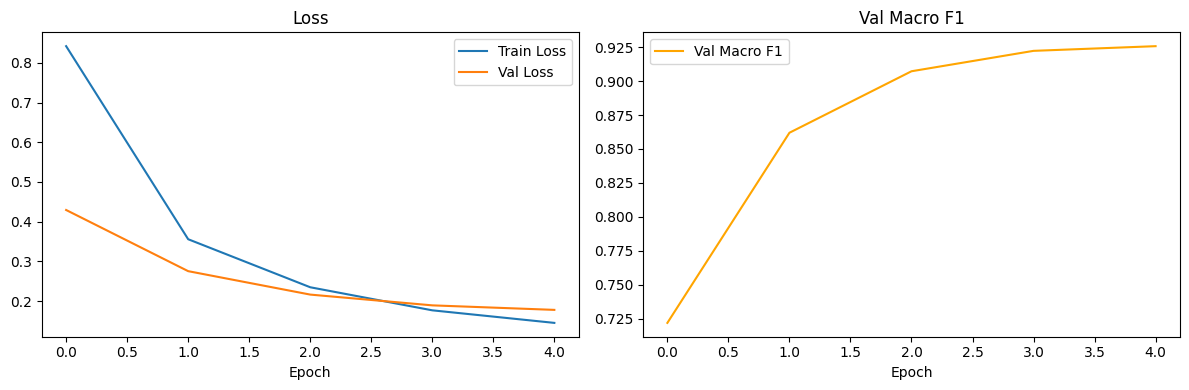

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].plot(history['val_loss'],   label='Val Loss')
axes[0].set_title('Loss'); axes[0].legend(); axes[0].set_xlabel('Epoch')

axes[1].plot(history['val_f1'], label='Val Macro F1', color='orange')
axes[1].set_title('Val Macro F1'); axes[1].legend(); axes[1].set_xlabel('Epoch')

plt.tight_layout()
plt.savefig(DATA_PATH + 'aspect_training_curves.png', dpi=150)
plt.show()

---
## STEP 10. Test set 최종 평가

In [14]:
model.load_state_dict(torch.load(best_model_path))
test_loss, test_f1, test_preds, test_labels = eval_epoch(model, test_loader, criterion, device)

print('=' * 60)
print('[STEP 10] Test set 최종 성능')
print('=' * 60)
print(f'Test Loss    : {test_loss:.4f}')
print(f'Test Macro F1: {test_f1:.4f}')
print()
print('[속성별 상세 성능]')
print(classification_report(
    test_labels, test_preds,
    target_names=list(mlb.classes_),
    digits=4,
    zero_division=0
))

Eval :   0%|          | 0/113 [00:00<?, ?it/s]

[STEP 10] Test set 최종 성능
Test Loss    : 0.2134
Test Macro F1: 0.9178

[속성별 상세 성능]
              precision    recall  f1-score   support

          가격     0.9560    0.9954    0.9753       437
       기능/효과     0.9034    0.8633    0.8829       856
         디자인     0.6316    0.9231    0.7500        13
         발림성     0.9688    0.9764    0.9725       254
     보습력/수분감     0.9402    0.9639    0.9519       832
         사용감     0.9459    0.9722    0.9589        36
          성분     0.8235    1.0000    0.9032        42
          용기     0.6351    0.8545    0.7287        55
          용량     0.9278    0.9709    0.9489       172
        유통기한     0.9661    1.0000    0.9828        57
    윤기/피부(톤)     0.9003    0.9538    0.9263       303
         자극성     0.9051    0.9597    0.9316       149
        제품구성     0.8703    0.9615    0.9136       286
          제형     0.9845    0.9845    0.9845       129
         지속력     0.8145    0.9266    0.8670       109
          탄력     0.8788    0.9457    0.9110        92

---
## STEP 11. 추론 함수 (Threshold 조정 포함)

In [15]:
def predict_aspects(text: str,
                    model,
                    tokenizer,
                    mlb,
                    device,
                    max_len=192,
                    threshold=0.6) -> dict:
                    ## threshold=0.5 → threshold=0.6
    """
    리뷰 텍스트를 입력받아 언급된 속성 목록을 반환

    threshold:
        낮추면 더 많은 속성 감지 (recall 올라감)
        높이면 확실한 속성만 감지 (precision 올라감)
    """
    model.eval()
    enc = tokenizer(
        text,
        add_special_tokens=True,
        max_length=max_len,
        padding='max_length',
        truncation=True,
        return_attention_mask=True,
        return_tensors='pt'
    )

    with torch.no_grad():
        logits = model(
            input_ids=enc['input_ids'].to(device),
            attention_mask=enc['attention_mask'].to(device)
        )

    probs = torch.sigmoid(logits)[0].cpu().numpy()
    detected = [(mlb.classes_[i], float(probs[i]))
                for i in range(len(mlb.classes_))
                if probs[i] > threshold]
    detected.sort(key=lambda x: x[1], reverse=True)

    return {
        'text'      : text,
        'threshold' : threshold,
        'detected'  : detected,
        'all_probs' : {mlb.classes_[i]: round(float(probs[i]), 4)
                       for i in range(len(mlb.classes_))}
    }


# 추론 테스트
test_cases = [
    '가격대비 너무 좋아요! 보습도 잘 되고 향기도 은은해요.',
    '흡수가 너무 느려서 아침에 쓰기가 불편해요. 가격도 비싸고.',
    '자극은 없는데 효과도 잘 모르겠어요. 그냥 무난한 것 같아요.',
    '발림성 좋고 보습력도 뛰어나요. 향이 좀 강한 게 아쉽네요.',
]

print('=' * 60)
print('[STEP 11] 추론 테스트 (threshold=0.5)')
print('=' * 60)
for text in test_cases:
    result = predict_aspects(text, model, tokenizer, mlb, device)
    print(f'리뷰  : {text}')
    print(f'감지된 속성: {[(a, f"{p:.3f}") for a, p in result["detected"]]}')
    print('-' * 50)

print()
print('=' * 60)
print('[Threshold 조정 비교]')
print('=' * 60)
sample_text = '발림성 좋고 보습력도 뛰어나요. 향이 좀 강한 게 아쉽네요.'
for thresh in [0.3, 0.5, 0.7]:
    result = predict_aspects(sample_text, model, tokenizer, mlb, device, threshold=thresh)
    aspects = [a for a, p in result['detected']]
    print(f'threshold={thresh}: {aspects}')
print()
print('→ threshold 낮추면 더 많은 속성 감지')
print('→ threshold 높이면 확실한 속성만 감지')



[STEP 11] 추론 테스트 (threshold=0.5)
리뷰  : 가격대비 너무 좋아요! 보습도 잘 되고 향기도 은은해요.
감지된 속성: [('향', '0.976'), ('가격', '0.930'), ('보습력/수분감', '0.873')]
--------------------------------------------------
리뷰  : 흡수가 너무 느려서 아침에 쓰기가 불편해요. 가격도 비싸고.
감지된 속성: [('흡수력', '0.941'), ('편의성/활용성', '0.940'), ('가격', '0.931')]
--------------------------------------------------
리뷰  : 자극은 없는데 효과도 잘 모르겠어요. 그냥 무난한 것 같아요.
감지된 속성: [('자극성', '0.979'), ('기능/효과', '0.860')]
--------------------------------------------------
리뷰  : 발림성 좋고 보습력도 뛰어나요. 향이 좀 강한 게 아쉽네요.
감지된 속성: [('향', '0.981'), ('발림성', '0.969'), ('보습력/수분감', '0.851')]
--------------------------------------------------

[Threshold 조정 비교]
threshold=0.3: ['향', '발림성', '보습력/수분감']
threshold=0.5: ['향', '발림성', '보습력/수분감']
threshold=0.7: ['향', '발림성', '보습력/수분감']

→ threshold 낮추면 더 많은 속성 감지
→ threshold 높이면 확실한 속성만 감지


In [16]:
# Threshold 비교 - 애매한 리뷰로 추가 테스트

sample_texts = [
    '전반적으로 무난한 것 같아요. 딱히 나쁘진 않은데 특별하지도 않아요.',
    '용기 디자인은 예쁜데 내용물은 그냥 그래요.',
    '향이 살짝 느껴지고 보습은 좀 되는 것 같기도 하고 아닌 것 같기도 해요.',
]

print('=' * 60)
print('[Threshold 조정 비교 - 애매한 리뷰]')
print('=' * 60)
for text in sample_texts:
    print(f'리뷰: {text}')
    for thresh in [0.3, 0.5, 0.7]:
        result = predict_aspects(text, model, tokenizer, mlb, device, threshold=thresh)
        aspects = [f'{a}({p:.2f})' for a, p in result['detected']]
        print(f'  threshold={thresh}: {aspects}')
    print()

[Threshold 조정 비교 - 애매한 리뷰]
리뷰: 전반적으로 무난한 것 같아요. 딱히 나쁘진 않은데 특별하지도 않아요.
  threshold=0.3: ['기능/효과(0.84)']
  threshold=0.5: ['기능/효과(0.84)']
  threshold=0.7: ['기능/효과(0.84)']

리뷰: 용기 디자인은 예쁜데 내용물은 그냥 그래요.
  threshold=0.3: ['용기(0.98)', '디자인(0.98)', '제품구성(0.52)', '기능/효과(0.49)', '용량(0.42)', '가격(0.37)', '품질(0.35)', '향(0.31)', '편의성/활용성(0.31)', '유통기한(0.30)']
  threshold=0.5: ['용기(0.98)', '디자인(0.98)', '제품구성(0.52)']
  threshold=0.7: ['용기(0.98)', '디자인(0.98)']

리뷰: 향이 살짝 느껴지고 보습은 좀 되는 것 같기도 하고 아닌 것 같기도 해요.
  threshold=0.3: ['향(0.98)', '보습력/수분감(0.91)']
  threshold=0.5: ['향(0.98)', '보습력/수분감(0.91)']
  threshold=0.7: ['향(0.98)', '보습력/수분감(0.91)']



In [17]:
# 새 셀로 추가
# threshold별 test set 성능 비교

print('=' * 60)
print('[Threshold별 Test set 성능 비교]')
print('=' * 60)

model.load_state_dict(torch.load(best_model_path))
model.eval()

all_probs, all_labels = [], []
with torch.no_grad():
    for batch in tqdm(test_loader, desc='Test', leave=False):
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['label']
        logits = model(input_ids, attention_mask)
        probs  = torch.sigmoid(logits).cpu().numpy()
        all_probs.append(probs)
        all_labels.append(labels.numpy())

all_probs  = np.vstack(all_probs)
all_labels = np.vstack(all_labels)

print(f'{"Threshold":>12}  {"Macro F1":>10}  {"Precision":>10}  {"Recall":>10}')
print('-' * 50)
for thresh in [0.3, 0.4, 0.5, 0.6, 0.7]:
    preds = (all_probs > thresh).astype(float)
    f1  = f1_score(all_labels, preds, average='macro', zero_division=0)
    pre = f1_score(all_labels, preds, average='macro', zero_division=0)
    from sklearn.metrics import precision_score, recall_score
    pre = precision_score(all_labels, preds, average='macro', zero_division=0)
    rec = recall_score(all_labels, preds, average='macro', zero_division=0)
    print(f'{thresh:>12.1f}  {f1:>10.4f}  {pre:>10.4f}  {rec:>10.4f}')

[Threshold별 Test set 성능 비교]


Test:   0%|          | 0/113 [00:00<?, ?it/s]

   Threshold    Macro F1   Precision      Recall
--------------------------------------------------
         0.3      0.8551      0.7738      0.9707
         0.4      0.8997      0.8483      0.9653
         0.5      0.9178      0.8842      0.9582
         0.6      0.9319      0.9178      0.9489
         0.7      0.9330      0.9346      0.9357


---
## STEP 12. 파이프라인 연결 미리보기

감정 분류기와 연결하는 방법 확인

In [18]:
# 파이프라인 연결 예시 (실제 pipeline.ipynb에서 사용)
# 여기서는 구조만 확인

print('=' * 60)
print('[STEP 12] 파이프라인 연결 구조 확인')
print('=' * 60)
print()
print('[파이프라인 흐름]')
print()

sample_text = '가격은 좀 비싸지만 보습력이 정말 좋고 흡수도 빨라요.'
result = predict_aspects(sample_text, model, tokenizer, mlb, device)

print(f'입력 리뷰: "{sample_text}"')
print()
print('[1단계] 속성 분류기 출력:')
for aspect, prob in result['detected']:
    print(f'  → {aspect} (확률: {prob:.3f})')

print()
print('[2단계] 감정 분류기 입력 (이렇게 연결됨):')
for aspect, prob in result['detected']:
    print(f'  tokenizer("{sample_text[:20]}...", "{aspect}") → 긍/부/중립')

print()
print('→ pipeline.ipynb에서 두 모델 불러와서 실제 연결 예정')

[STEP 12] 파이프라인 연결 구조 확인

[파이프라인 흐름]

입력 리뷰: "가격은 좀 비싸지만 보습력이 정말 좋고 흡수도 빨라요."

[1단계] 속성 분류기 출력:
  → 흡수력 (확률: 0.966)
  → 가격 (확률: 0.934)
  → 보습력/수분감 (확률: 0.891)

[2단계] 감정 분류기 입력 (이렇게 연결됨):
  tokenizer("가격은 좀 비싸지만 보습력이 정말 좋...", "흡수력") → 긍/부/중립
  tokenizer("가격은 좀 비싸지만 보습력이 정말 좋...", "가격") → 긍/부/중립
  tokenizer("가격은 좀 비싸지만 보습력이 정말 좋...", "보습력/수분감") → 긍/부/중립

→ pipeline.ipynb에서 두 모델 불러와서 실제 연결 예정
